Install Ultralytics and Pytorch, verify GPU access

In [ ]:
!pip install -q ultralytics

# Verify that the T4 GPU is assigned and active
import torch
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device Name: {torch.cuda.get_device_name(0)}")

PyTorch Version: 2.11.0+cu130
CUDA Available: True
Device Name: Tesla T4


Mount Google Drive for data storage

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
# Create a dedicated directory in Drive
save_dir = "/content/drive/MyDrive/SDP_Practice"
os.makedirs(save_dir, exist_ok=True)
print(f"Output directory ready: {save_dir}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Output directory ready: /content/drive/MyDrive/SDP_Practice


Train on GPU and direct checkpoints to Drive

In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="2xM26T0HzbOfzA4v4tEI")
project = rf.workspace("ellistons-workspace").project("sdp-team-21")
version = project.version(5)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...


In [ ]:
from ultralytics import YOLO

# Load pre-trained checkpoint (enables transfer learning)
model = YOLO("yolov8n.pt")

# Train on custom boiler dataset
results = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=60,
    imgsz=640,
    batch=8,
    device=0,
    pretrained=True,
    project=save_dir,
    name="boiler_tuned_hparams",

    box=10.0,             # Emphasize precision on tight bounding boxes
    cls=1.5,              # Boost classification penalty for missing small classes
    dfl=2.0,              # Refine edge distribution for cluttered pipe backgrounds

    mosaic=0.0,           # Disable 4-image tiling to keep gauge pixel size large
    scale=0.2,            # Prevent excessive downscaling zoom
    fliplr=0.5,           # Allow horizontal reflection
    flipud=0.0,           # Respect gravity (boilers are ground-mounted)

    lr0=0.003,            # Gentle learning rate for fine-tuning pre-trained weights
    lrf=0.01,
    warmup_epochs=5.0,

    exist_ok=True,
    verbose=True
)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=10.0, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=1.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SDP-Team-21-5/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=2.0, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.003, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=boiler_tuned_hparams, nbs=64, nms=None, opset=None, opti

Test inference and display the output inline


image 1/1 /content/SDP-Team-21-5/valid/images/steam-boiler-types-and-usage-areas_webp.rf.421741f37cedb515948d1d77b67b803f.jpg: 640x640 1 Boiler, 12.5ms
Speed: 0.9ms preprocess, 12.5ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/drive/MyDrive/SDP_Practice/boiler_inference_output

--- Detections for steam-boiler-types-and-usage-areas_webp.rf.421741f37cedb515948d1d77b67b803f.jpg ---
Total objects identified: 1
  • Boiler (confidence: 99.42%)


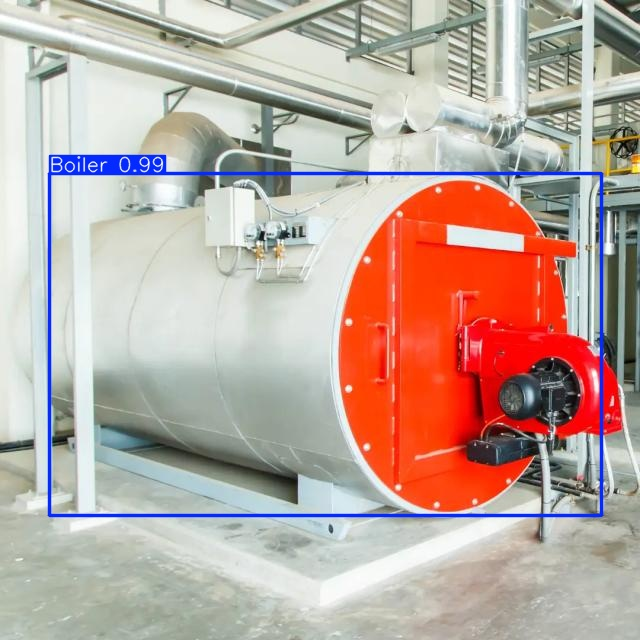

In [ ]:
import glob
import os
from PIL import Image

# Point directly to the weights from the transfer run
best_weights = os.path.join(save_dir, "boiler_transfer_v1", "weights", "best.pt")
trained_model = YOLO(best_weights)

# Retrieve a valid image from test or valid split
candidate_images = (
    glob.glob(f"{dataset.location}/valid/images/*.*") or
    glob.glob(f"{dataset.location}/train/images/*.*")
)

sample_image = candidate_images[0]
image_name = os.path.basename(sample_image)

# Run inference
pred_results = trained_model.predict(
    source=sample_image,
    conf=0.50,
    iou=0.50,
    save=True,
    project=save_dir,
    name="boiler_inference_output",
    exist_ok=True
)

# Print detected classes and confidence values
boxes = pred_results[0].boxes
print(f"\n--- Detections for {image_name} ---")
print(f"Total objects identified: {len(boxes)}")
for box in boxes:
    cls_id = int(box.cls[0].item())
    label = trained_model.names[cls_id]
    conf_score = float(box.conf[0].item())
    print(f"  • {label} (confidence: {conf_score:.2%})")

# Render output image inline
output_path = os.path.join(pred_results[0].save_dir, image_name)
display(Image.open(output_path))